# 05 — Regression: Next-week recorded sales

This notebook predicts how many recorded units an article will sell in the following week using information available at the end of the current week. It builds on the article-week dataset from notebook 02 and the regression EDA in notebook 03. One row represents an article-week with at least one current sale. Because stock availability is unknown, recorded sales are not necessarily total customer demand.

## Objectives

- Establish simple, reproducible baselines before fitting any model.
- Train and compare regularized linear regression, a decision tree, Random Forest, and boosting with the same predictors and training sample.
- Evaluate MAE and RMSE, with R² as supplementary context, on later validation weeks.
- Examine whether errors change across time, sales levels, and product groups.
- Select a provisional candidate without using the final test set; systematic tuning and final evaluation belong in notebook 07.

**Computational scope:** Each model uses the same reproducible sample of up to 100,000 training rows (seed 42) so the notebook can run on a personal computer. Every validation row is evaluated. Results describe this training budget, not models trained on the entire training set.


## 1. Reproducible setup and data contract

Load the complete publication selected by `CURRENT.json`, verify its SHA-256 checksum, and read only the columns needed for regression. Article IDs remain text for auditing and are not used as numeric predictors. The target is next-week **recorded sales**; the chronological split was defined in notebook 02.


In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/data/process_data.py").is_file()
             and (p / "data/processed/CURRENT.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open fashion-demand-ml and run notebook 02 first.")
processed = ROOT / "data/processed"
pointer = json.loads((processed / "CURRENT.json").read_text(encoding="utf-8"))
run = (processed / pointer["run_dir"]).resolve()
if pointer.get("preview") or not run.is_relative_to(processed.resolve()):
    raise ValueError("CURRENT.json does not point to a valid complete publication.")
checksums = json.loads((run / "checksums.json").read_text(encoding="utf-8"))
csv_path = run / "article_week.csv.gz"
digest = hashlib.sha256()
with csv_path.open("rb") as source:
    for block in iter(lambda: source.read(1024 * 1024), b""):
        digest.update(block)
expected = checksums["article_week.csv.gz"]
if isinstance(expected, dict):
    expected = expected.get("sha256")
if digest.hexdigest() != expected:
    raise ValueError("The CSV does not match its published SHA-256 checksum.")

numeric = ["sales", "lag_1_sales", "lag_4_sales", "rolling_4w_sales_mean",
           "rolling_12w_sales_mean", "mean_price", "online_share", "iso_week"]
categorical = ["product_group_name", "garment_group_name", "index_group_name"]
columns = ["article_id", "target_week", "split", "target_next_week_sales", *numeric, *categorical]
data = pd.read_csv(csv_path, usecols=columns, dtype={"article_id": "string"},
                   parse_dates=["target_week"])
assert data["target_next_week_sales"].notna().all()
assert set(data["split"]) == {"train", "validation", "test"}
print("Publication:", run.name)
print("Rows by split:")
print(data["split"].value_counts().to_string())


Publication: 20261020T154621-9be94fc7
Rows by split:
split
train         1326434
test           289490
validation     271215


## 2. Chronological split and simple baselines

Training weeks precede validation weeks. The first baseline predicts that next-week sales equal current-week sales; this persistence rule was already used in the original data-review notebook. The second predicts the mean of the four historical weeks. Neither uses future information or needs model fitting. Both are evaluated on the same validation rows as the trained models.

MAE is the average absolute error in units per article-week. RMSE gives more weight to large misses. R² is supplementary and can be negative. Lower MAE and RMSE are better. The final comparison table appears in section 4.


In [2]:
train = data.loc[data["split"].eq("train")].copy()
validation = data.loc[data["split"].eq("validation")].copy()
del data  # Release the full table; final-test outcomes are not inspected.
assert train["target_week"].max() < validation["target_week"].min()

SEED = 42
MAX_TRAIN_ROWS = 100_000
train_sample = train.sample(n=min(MAX_TRAIN_ROWS, len(train)), random_state=SEED)
print("Available training rows:", len(train))
print("Rows used to fit each model:", len(train_sample))
print("Full validation rows:", len(validation))
print("Validation weeks:", validation["target_week"].nunique())
print("Predictors:", numeric + categorical)

def scores(y, prediction):
    return {"MAE": mean_absolute_error(y, prediction),
            "RMSE": np.sqrt(mean_squared_error(y, prediction)),
            "R2": r2_score(y, prediction)}

truth = validation["target_next_week_sales"].to_numpy()
predictions = {
    "Repeat current-week sales": validation["sales"].to_numpy(dtype=float),
    "Four-week historical mean": validation["rolling_4w_sales_mean"].to_numpy(dtype=float),
}
print("Baselines ready: current-week sales and the four-week historical mean.")


Available training rows: 1326434
Rows used to fit each model: 100000
Full validation rows: 271215
Validation weeks: 15
Predictors: ['sales', 'lag_1_sales', 'lag_4_sales', 'rolling_4w_sales_mean', 'rolling_12w_sales_mean', 'mean_price', 'online_share', 'iso_week', 'product_group_name', 'garment_group_name', 'index_group_name']
Baselines ready: current-week sales and the four-week historical mean.


## 3. Preprocessing and candidate models

Missing numeric values are filled with the training median; missing categories use the training mode. Categorical names are one-hot encoded, and numeric predictors are scaled. A scikit-learn `Pipeline` learns these operations from the training sample only, then applies them to validation data. Identifiers, split labels, dates, and future outcomes are excluded from predictors.

The four model families follow the regression options in the project brief: regularized linear regression (Ridge), a decision tree, Random Forest, and boosting. All use the same 100,000-row training sample, predictors, and validation set. Hyperparameters here are modest initial settings, not an optimized search. Predictions below zero are counted and clipped to zero before scoring because negative unit sales are impossible; the rule is identical for all models.


In [3]:
preprocess = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric),
    ("categorical", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical),
], sparse_threshold=0)

estimators = {
    "Ridge": Ridge(alpha=10.0),
    "Decision tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=30, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=40, max_depth=14,
                                           min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "Boosting": HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=31,
                                               learning_rate=0.08, random_state=SEED),
}
models = {}
negative_counts = {}
for name, estimator in estimators.items():
    model = Pipeline([("prepare", preprocess), ("model", estimator)])
    model.fit(train_sample[numeric + categorical], train_sample["target_next_week_sales"])
    raw_prediction = model.predict(validation[numeric + categorical])
    negative_counts[name] = int((raw_prediction < 0).sum())
    predictions[name] = np.clip(raw_prediction, 0, None)
    models[name] = model
    print(f"{name}: MAE={mean_absolute_error(truth, predictions[name]):.3f}; "
          f"negative predictions before clipping={negative_counts[name]:,}")


Ridge: MAE=8.183; negative predictions before clipping=8,215
Decision tree: MAE=7.843; negative predictions before clipping=0
Random Forest: MAE=7.580; negative predictions before clipping=0
Boosting: MAE=7.584; negative predictions before clipping=5


## 4. Model comparison on validation data

The first table is the main result: one row per baseline or model, sorted by MAE. Every score uses the **full validation set**. Values are shown to three decimal places so close results are distinguishable. The highlighted row has the lowest MAE; it is a provisional candidate, not a final winner.

The second table divides validation into three consecutive blocks of whole weeks. It shows whether a good overall average hides a difficult period. These blocks describe variation in the fixed validation period; the nested chronological validation required for parameter selection is developed in notebook 07.


In [4]:
from html import escape
from IPython.display import HTML, display

weeks = np.sort(validation["target_week"].unique())
windows = np.array_split(weeks, 3)
rows = []
for name, prediction in predictions.items():
    rows.append({"model_name": name, "window": "full", "rows": len(validation),
                 **scores(truth, prediction)})
    for i, block in enumerate(windows, start=1):
        mask = validation["target_week"].isin(block).to_numpy()
        rows.append({"model_name": name,
                     "window": f"{i}: {pd.Timestamp(block[0]):%d/%m/%Y}–{pd.Timestamp(block[-1]):%d/%m/%Y}",
                     "rows": int(mask.sum()), **scores(truth[mask], prediction[mask])})
results = pd.DataFrame(rows)
complete = results.loc[results["window"].eq("full")].sort_values("MAE").copy()
baseline_names = {"Repeat current-week sales", "Four-week historical mean"}

def metric_table(frame, caption, highlight=None, show_window=False):
    """Show a clear notebook table without requiring optional styling packages."""
    headers = ["Method", "Type", "Validation rows", "MAE (units)",
               "RMSE (units)", "R²"]
    if show_window:
        headers.insert(1, "Validation window")
    head = "".join(f"<th>{escape(label)}</th>" for label in headers)
    body = []
    for row in frame.itertuples(index=False):
        name = row.model_name
        is_baseline = name in baseline_names
        is_best = name == highlight
        background = "#EAF1FF" if is_best else "#F2F4F7" if is_baseline else "#FFFFFF"
        weight = "600" if is_best else "400"
        cells = [escape(name)]
        if show_window:
            cells.append(escape(row.window))
        cells.extend(["Baseline" if is_baseline else "Model", f"{row.rows:,}",
                      f"{row.MAE:.3f}", f"{row.RMSE:.3f}", f"{row.R2:.3f}"])
        fields = "".join(
            f'<td style="padding:8px 11px;border-bottom:1px solid #DDE3EA;'
            f'text-align:{"left" if i < (3 if show_window else 2) else "right"};">{value}</td>'
            for i, value in enumerate(cells)
        )
        body.append(f'<tr style="background:{background};font-weight:{weight};">{fields}</tr>')
    html = (f'<div style="overflow-x:auto;margin:12px 0 18px;font-family:Arial, sans-serif;">'
            f'<table style="border-collapse:collapse;width:100%;font-size:13px;color:#17212B;">'
            f'<caption style="caption-side:top;text-align:left;font-weight:600;font-size:15px;'
            f'padding:0 0 10px;">{escape(caption)}</caption>'
            f'<thead style="background:#E7EBF0;"><tr>{head}</tr></thead>'
            f'<tbody>{"".join(body)}</tbody></table></div>')
    display(HTML(html))

candidate_name = complete.loc[~complete["model_name"].isin(baseline_names)].iloc[0]["model_name"]
metric_table(complete, "Full validation · lower MAE and RMSE are better", highlight=candidate_name)
window_results = results.loc[results["window"].ne("full")].sort_values(["model_name", "window"])
metric_table(window_results, "Scores by consecutive validation window", show_window=True)


Method,Type,Validation rows,MAE (units),RMSE (units),R²
Random Forest,Model,"271,215",7.580,22.951,0.639
Boosting,Model,"271,215",7.584,23.278,0.628
Decision tree,Model,"271,215",7.843,23.854,0.610
Repeat current-week sales,Baseline,"271,215",8.113,25.638,0.549
Ridge,Model,"271,215",8.183,23.610,0.618
Four-week historical mean,Baseline,"271,215",11.419,32.276,0.285


Method,Validation window,Type,Validation rows,MAE (units),RMSE (units),R²
Boosting,1: 02/03/2020–30/03/2020,Model,"92,900",6.890,20.754,0.620
Boosting,2: 06/04/2020–04/05/2020,Model,"76,004",9.643,29.923,0.551
Boosting,3: 11/05/2020–08/06/2020,Model,"102,311",6.686,19.498,0.718
Decision tree,1: 02/03/2020–30/03/2020,Model,"92,900",7.057,21.250,0.601
Decision tree,2: 06/04/2020–04/05/2020,Model,"76,004",9.902,30.616,0.530
Decision tree,3: 11/05/2020–08/06/2020,Model,"102,311",7.028,20.050,0.702
Four-week historical mean,1: 02/03/2020–30/03/2020,Baseline,"92,900",10.022,27.583,0.328
Four-week historical mean,2: 06/04/2020–04/05/2020,Baseline,"76,004",14.988,41.121,0.152
Four-week historical mean,3: 11/05/2020–08/06/2020,Baseline,"102,311",10.037,28.540,0.396
Random Forest,1: 02/03/2020–30/03/2020,Model,"92,900",6.827,20.460,0.630


## 5. Error analysis and diagnostic figures

The first chart compares each method's validation MAE with the baselines. The second figure uses **two bar charts** instead of a logarithmic observed-versus-predicted plot. Its left panel compares average observed and predicted sales; its right panel shows MAE. Both panels group validation rows by **observed next-week sales** (0, 1–5, 6–20, and more than 20 units). These groups are diagnostic only: observed future sales are never used as model predictors. The plots and tables use **all** validation rows.

The tables below also report errors by product group and selected weeks. Groups with very few rows should be interpreted cautiously.


Candidate with the lowest validation MAE: Random Forest


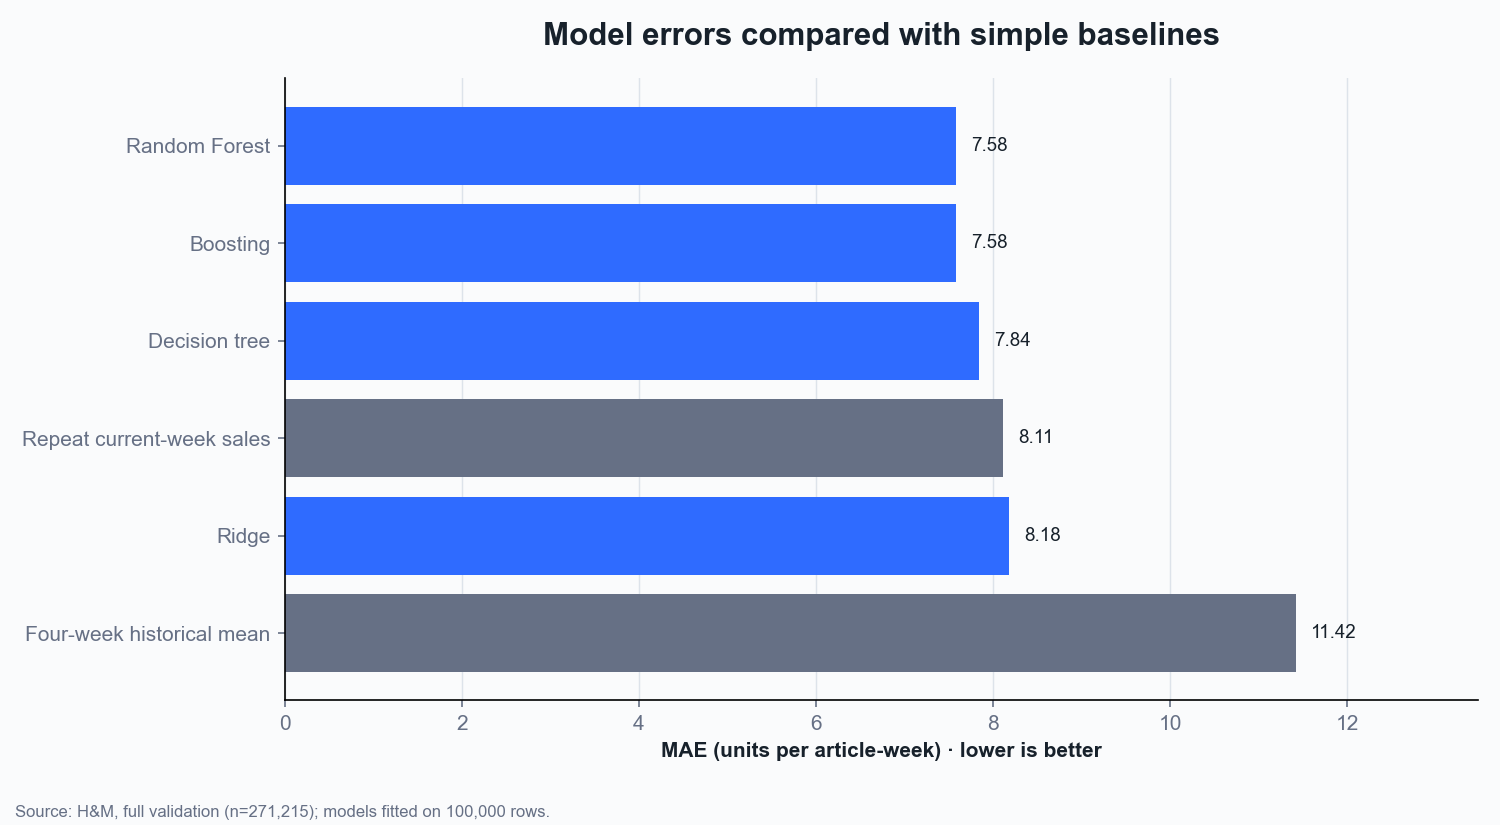

In [5]:
from matplotlib import font_manager

available = {font.name for font in font_manager.fontManager.ttflist}
font = next((name for name in ["Arial", "Liberation Sans", "DejaVu Sans"] if name in available), "DejaVu Sans")
plt.rcParams.update({"font.family": font, "figure.facecolor": "#FAFBFC",
                     "axes.facecolor": "#FAFBFC", "text.color": "#17212B",
                     "axes.labelcolor": "#17212B", "xtick.color": "#667085", "ytick.color": "#667085"})

complete = results.loc[results["window"].eq("full")].sort_values("MAE")
names = complete["model_name"].tolist()
errors = complete["MAE"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ["#667085" if name in ["Repeat current-week sales", "Four-week historical mean"]
          else "#2F6BFF" for name in names]
ax.barh(names[::-1], errors[::-1], color=colors[::-1])
ax.set_xlim(0, max(errors) * 1.18)
ax.set_xlabel("MAE (units per article-week) · lower is better", fontsize=10, fontweight="bold")
ax.set_title("Model errors compared with simple baselines", fontsize=15, fontweight="bold", pad=16)
ax.grid(axis="x", color="#DDE3EA", linewidth=0.7)
ax.set_axisbelow(True)
for spine in ["top", "right"]: ax.spines[spine].set_visible(False)
for y, value in enumerate(errors[::-1]):
    ax.text(value + max(errors) * 0.015, y, f"{value:.2f}", va="center", fontsize=9)
fig.text(0.01, 0.01, f"Source: H&M, full validation (n={len(validation):,}); models fitted on {len(train_sample):,} rows.",
         fontsize=8, color="#667085")
fig.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()

model_only = complete.loc[~complete["model_name"].isin(["Repeat current-week sales", "Four-week historical mean"])]
chosen = model_only.iloc[0]["model_name"]
print("Candidate with the lowest validation MAE:", chosen)



Errors by observed next-week sales group:
                rows     MAE
demand_level                
0              60686   1.953
1–5           101538   2.530
6–20           62358   6.346
>20            46633  27.549

Errors by product_group_name:
                         rows     MAE
product_group_name                   
Unknown                   582  14.678
Swimwear                14739  14.212
Underwear               18019   9.696
Garment Lower body      58243   7.970
Garment Full body       38300   7.503
Garment Upper body     100331   7.065
Nightwear                3627   6.685
Socks & Tights           4872   6.363
Items                      38   5.598
Shoes                   10622   4.732
Accessories             21588   4.458
Stationery                 21   4.351
Bags                      117   3.935
Garment and Shoe care      40   1.961
Interior textile            2   1.225
Underwear/nightwear        22   1.147
Cosmetic                   37   0.994
Furniture                  15 

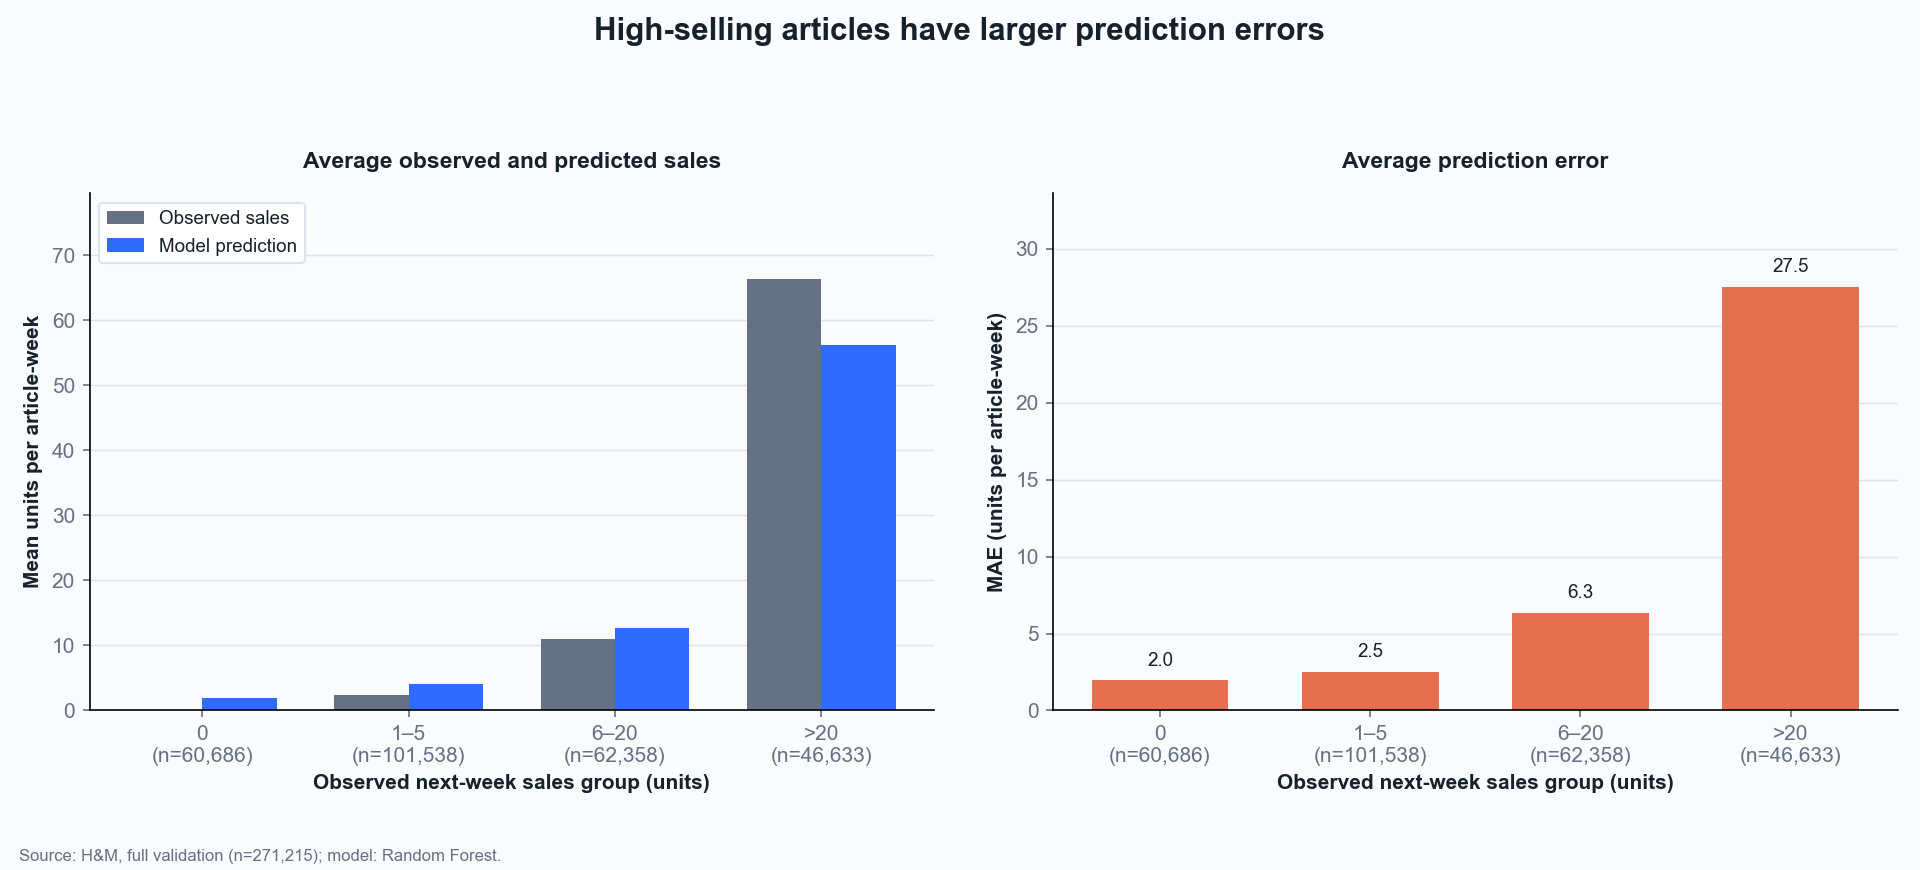

In [6]:
diagnostics = validation[["target_week", "product_group_name", "target_next_week_sales"]].copy()
diagnostics["prediction"] = predictions[chosen]
diagnostics["absolute_error"] = np.abs(diagnostics["target_next_week_sales"] - diagnostics["prediction"])
diagnostics["demand_level"] = pd.cut(diagnostics["target_next_week_sales"],
                                       bins=[-1, 0, 5, 20, np.inf],
                                       labels=["0", "1–5", "6–20", ">20"])

# A simple diagnostic: how close are average predictions in each observed-sales group?
by_demand = diagnostics.groupby("demand_level", observed=True).agg(
    rows=("absolute_error", "size"),
    observed_mean=("target_next_week_sales", "mean"),
    predicted_mean=("prediction", "mean"),
    MAE=("absolute_error", "mean"),
)
labels = by_demand.index.astype(str).tolist()
positions = np.arange(len(labels))
width = 0.36
fig, (ax_actual, ax_error) = plt.subplots(1, 2, figsize=(12.8, 5.8))

ax_actual.bar(positions - width / 2, by_demand["observed_mean"], width,
              color="#667085", label="Observed sales")
ax_actual.bar(positions + width / 2, by_demand["predicted_mean"], width,
              color="#2F6BFF", label="Model prediction")
ax_actual.set_title("Average observed and predicted sales", fontsize=11, fontweight="bold", pad=12)
ax_actual.set_ylabel("Mean units per article-week", fontsize=10, fontweight="bold")
ax_actual.set_ylim(0, max(by_demand["observed_mean"].max(), by_demand["predicted_mean"].max()) * 1.2)
ax_actual.legend(loc="upper left", facecolor="white", edgecolor="#DDE3EA", framealpha=1, fontsize=9)

bars = ax_error.bar(positions, by_demand["MAE"], width=0.65, color="#E76F51")
ax_error.set_title("Average prediction error", fontsize=11, fontweight="bold", pad=12)
ax_error.set_ylabel("MAE (units per article-week)", fontsize=10, fontweight="bold")
ax_error.set_ylim(0, by_demand["MAE"].max() * 1.22)
for bar, value in zip(bars, by_demand["MAE"]):
    ax_error.text(bar.get_x() + bar.get_width() / 2, value + by_demand["MAE"].max() * 0.025,
                  f"{value:.1f}", ha="center", va="bottom", fontsize=9)

for ax in (ax_actual, ax_error):
    ax.set_xticks(positions, [f"{label}\n(n={count:,})" for label, count in zip(labels, by_demand["rows"])])
    ax.set_xlabel("Observed next-week sales group (units)", fontsize=10, fontweight="bold")
    ax.grid(axis="y", color="#DDE3EA", linewidth=0.7)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
fig.suptitle("High-selling articles have larger prediction errors", fontsize=15, fontweight="bold", y=0.98)
fig.text(0.01, 0.01, f"Source: H&M, full validation (n={len(validation):,}); model: {chosen}.",
         fontsize=8, color="#667085")
fig.tight_layout(rect=(0, 0.055, 1, 0.91), w_pad=2.5)
plt.show()

print("\nErrors by observed next-week sales group:")
print(by_demand[["rows", "MAE"]].round(3).to_string())
for group in ["product_group_name", "target_week"]:
    summary = diagnostics.groupby(group, observed=True)["absolute_error"].agg(rows="size", MAE="mean")
    if group == "target_week":
        print("\nErrors by week (first and last):")
        print(pd.concat([summary.head(3), summary.tail(3)]).round(3).to_string())
    else:
        print(f"\nErrors by {group}:")
        print(summary.sort_values("MAE", ascending=False).round(3).to_string())


## 6. Evidence-based conclusions and next phase

The current-week persistence baseline is already informative: an article's sales this week often help predict its recorded sales next week. In this publication, its validation MAE is **8.113 units per article-week**. The provisional Random Forest candidate reaches **7.580**, a reduction of **0.533 units (6.6%)**. RMSE also falls from **25.638 to 22.951 units**, indicating fewer or smaller large misses overall. These gains are useful but modest relative to a strong simple baseline.

The four-week historical mean is a second, weaker reference (MAE **11.419**). Replacing the persistence baseline with this weaker rule would make the percentage improvement look larger without improving the model. Both references should remain visible, with persistence as the stronger practical comparison.

Errors are uneven: validation rows with more than 20 recorded next-week sales have a much higher MAE than low-sales rows. The fixed sample of 100,000 training rows may also limit performance, but that is a hypothesis to test rather than an established explanation. Promotions, stock availability, and other unobserved factors may further limit predictability; recorded sales cannot reveal unmet demand.

**Next experiments, keeping the same chronological validation and baselines:**

- Increase the training sample toward the full available training set and measure both error and runtime.
- Tune model settings with the chronological nested-validation procedure in notebook 07.
- Test approaches suited to skewed count outcomes or high-sales articles, then compare errors on the original unit scale and across product groups.

None of these changes is guaranteed to reduce error. The provisional candidate was selected using validation MAE; RMSE, time-window variation, and segment errors remain part of the assessment. The final test set must stay untouched until the design is fixed. Weeks without a current sale are outside the supervised population used here. Predictive relationships are not interpreted as causal effects.


In [7]:
baseline_mae = float(complete.loc[complete["model_name"].eq("Repeat current-week sales"), "MAE"].iloc[0])
candidate_row = complete.loc[complete["model_name"].eq(chosen)].iloc[0]
improvement = 100 * (baseline_mae - candidate_row["MAE"]) / baseline_mae
window_mae = results.loc[(results["model_name"].eq(chosen)) & (results["window"].ne("full")), "MAE"]
print(f"Provisional candidate: {chosen}.")
print(f"MAE: {candidate_row['MAE']:.2f} units; RMSE: {candidate_row['RMSE']:.2f} units; R²: {candidate_row['R2']:.3f}.")
print(f"MAE improvement over repeating current-week sales: {improvement:+.1f}% (positive means better).")
print(f"MAE across windows: {window_mae.min():.2f}–{window_mae.max():.2f} units.")
print("The choice is provisional: models used a development sample and the final test set remains reserved.")


Provisional candidate: Random Forest.
MAE: 7.58 units; RMSE: 22.95 units; R²: 0.639.
MAE improvement over repeating current-week sales: +6.6% (positive means better).
MAE across windows: 6.70–9.69 units.
The choice is provisional: models used a development sample and the final test set remains reserved.
